# 01 — Data exploration and the engagement-band baseline

**Question:** how well does a descriptive engagement score (how active a student is right now, compared with their cohort) pick out the students who will withdraw or need support?

This is stage 1 of the project: the baseline that later models have to beat.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from eew.config import PROCESSED_DIR, RESULTS_DIR, PREDICTION_WEEKS, CONTACT_CAPACITY
from eew import population as P, baseline as B, evaluate as E

FIG = pathlib.Path.cwd().parent / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
enr = pd.read_parquet(PROCESSED_DIR / "enrolments.parquet")
daily = pd.read_parquet(PROCESSED_DIR / "daily_clicks.parquet")
print(f"{len(enr):,} enrolments, {len(daily):,} enrolment-days with clicks")
enr.final_result.value_counts()

32,593 enrolments, 1,808,119 enrolment-days with clicks


final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

## 1. Who can an early-warning system help?

A quarter of withdrawals happen before the module starts, when there is no in-course behaviour to learn from. These are excluded from model metrics and reported separately.

{'withdrawn_total': 10156, 'withdrawn_before_start': 2676, 'withdrawn_no_date': 93}
Early-warning population: 29,824 enrolments, withdrawal rate 24.8%


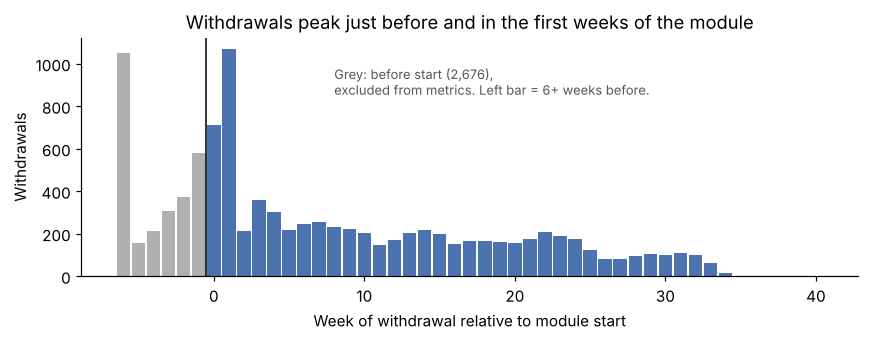

Median withdrawal week (population): 9.0


In [2]:
print(P.excluded_summary(enr))
pop = P.early_warning_population(enr)
print(f"Early-warning population: {len(pop):,} enrolments, withdrawal rate {pop.withdrawn.mean():.1%}")

w = enr.loc[enr.withdrawn, "withdrawal_day"].dropna() // 7
fig, ax = plt.subplots(figsize=(8, 3.2))
counts = w.clip(-6, 40).value_counts().reindex(range(-6, 41), fill_value=0)
ax.bar(counts.index, counts.values, width=0.9,
       color=["#b0b0b0" if i < 0 else "#4C72B0" for i in counts.index])
ax.axvline(-0.5, color="black", lw=1)
ax.text(8, counts.max() * 0.8, f"Grey: before start ({int(counts[counts.index < 0].sum()):,}),\nexcluded from metrics. Left bar = 6+ weeks before.",
        fontsize=8.5, color="#555")
ax.set(xlabel="Week of withdrawal relative to module start", ylabel="Withdrawals",
       title="Withdrawals peak just before and in the first weeks of the module")
fig.tight_layout(); fig.savefig(FIG / "withdrawal_timing.png"); plt.show()
print("Median withdrawal week (population):", (pop.loc[pop.withdrawn, "withdrawal_day"] // 7).median())

## 2. How does engagement differ by outcome?

Median weekly clicks for each final result. Withdrawn students are counted only while still enrolled.

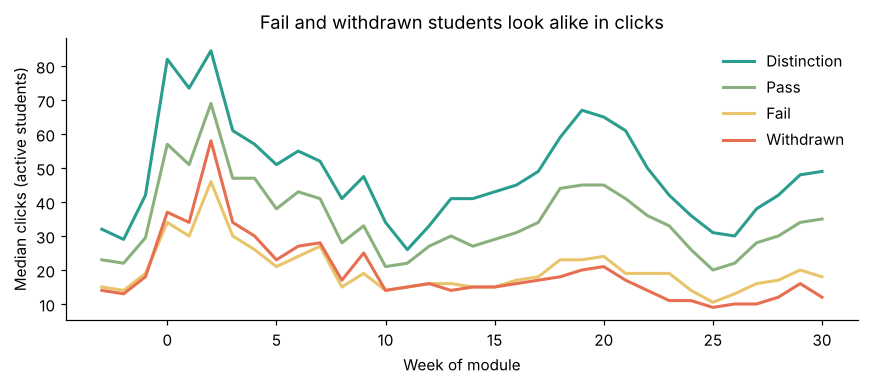

In [3]:
d = daily.merge(enr[["code_module", "code_presentation", "id_student", "final_result", "withdrawal_day"]])
d = d[d.withdrawal_day.isna() | (d.day < d.withdrawal_day)]
d["week"] = d.day // 7
wk = d.groupby(["code_module", "code_presentation", "id_student", "final_result", "week"]).clicks.sum().reset_index()
med = wk[wk.week.between(-3, 30)].groupby(["final_result", "week"]).clicks.median().unstack(0)
fig, ax = plt.subplots(figsize=(8, 3.6))
colours = {"Distinction": "#2a9d8f", "Pass": "#8ab17d", "Fail": "#e9c46a", "Withdrawn": "#e76f51"}
for res in ["Distinction", "Pass", "Fail", "Withdrawn"]:
    ax.plot(med.index, med[res], label=res, color=colours[res], lw=2)
ax.set(xlabel="Week of module", ylabel="Median clicks (active students)", title="Fail and withdrawn students look alike in clicks")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "weekly_clicks_by_outcome.png"); plt.show()

## 3. The engagement-band baseline

At each prediction week *k*, using only clicks before day 7*k*:

* **Band (7-day):** last-7-day clicks banded as none, low, medium, high or very high, relative to active students on the same module presentation.
* **Cumulative:** total clicks since the start, as a cohort percentile.

Evaluation uses a **contact capacity of 10% of each cohort per week**: the team can contact the top 10% by risk.

In [4]:
ar4 = B.baseline_scores(daily, P.at_risk(pop, 4), 4)
tab = ar4.groupby("band", observed=True).agg(students=("band", "size"),
        withdraw_rate=("will_withdraw", "mean"), needs_support_rate=("needs_support", "mean"))
tab["share"] = tab.students / tab.students.sum()
tab.style.format({"withdraw_rate": "{:.1%}", "needs_support_rate": "{:.1%}", "share": "{:.1%}"})

,students,withdraw_rate,needs_support_rate,share
band,,,,
none,5833,22.1%,64.2%,21.2%
low,5270,22.1%,52.1%,19.2%
medium,10981,17.5%,37.8%,40.0%
high,3224,12.6%,28.2%,11.7%
very high,2160,11.3%,24.8%,7.9%


In [5]:
last_active = P.last_activity_day(daily, pop)
rows = []
for k in PREDICTION_WEEKS:
    df = P.add_last_activity(B.baseline_scores(daily, P.at_risk(pop, k), k), last_active)
    for target in ["will_withdraw", "needs_support"]:
        for score, name in [("risk_band7", "Engagement band (7-day)"), ("risk_cum", "Cumulative clicks")]:
            rows.append({"week": k, "target": target, "baseline": name,
                         **E.capacity_metrics(df, score, CONTACT_CAPACITY, target)})
res = pd.DataFrame(rows)
res.to_csv(RESULTS_DIR / "baseline_metrics.csv", index=False)
cols = ["precision", "precision_lo", "precision_hi", "base_rate", "lift", "recall", "recall_lo", "recall_hi", "auc"]
res.set_index(["target", "baseline", "week"])[cols].round(3)

precision  precision_lo  \
target        baseline                week                            
will_withdraw Engagement band (7-day) 2         0.279         0.239   
              Cumulative clicks       2         0.297         0.253   
needs_support Engagement band (7-day) 2         0.703         0.652   
              Cumulative clicks       2         0.756         0.703   
will_withdraw Engagement band (7-day) 4         0.264         0.223   
              Cumulative clicks       4         0.272         0.230   
needs_support Engagement band (7-day) 4         0.699         0.639   
              Cumulative clicks       4         0.797         0.750   
will_withdraw Engagement band (7-day) 6         0.236         0.199   
              Cumulative clicks       6         0.240         0.203   
needs_support Engagement band (7-day) 6         0.703         0.644   
              Cumulative clicks       6         0.811         0.765   
will_withdraw Engagement band (7-day) 8         0.226         0.195   
              Cumulative clicks       8         0.223         0.190   
needs_support Engagement band (7-day) 8         0.728         0.673   
              Cumulative clicks       8         0.833         0.787   
will_withdraw Engagement band (7-day) 10        0.202         0.167   
              Cumulative clicks       10        0.196         0.165   
needs_support Engagement band (7-day) 10        0.689         0.620   
              Cumulative clicks       10        0.846         0.798   
will_withdraw Engagement band (7-day) 12        0.155         0.131   
              Cumulative clicks       12        0.173         0.147   
needs_support Engagement band (7-day) 12        0.598         0.517   
              Cumulative clicks       12        0.847         0.798   

                                            precision_hi  base_rate   lift  \
target        baseline                week                                   
will_withdraw Engagement band (7-day) 2            0.319      0.200  1.397   
              Cumulative clicks       2            0.342      0.200  1.487   
needs_support Engagement band (7-day) 2            0.746      0.451  1.557   
              Cumulative clicks       2            0.797      0.451  1.674   
will_withdraw Engagement band (7-day) 4            0.306      0.183  1.444   
              Cumulative clicks       4            0.319      0.183  1.487   
needs_support Engagement band (7-day) 4            0.756      0.440  1.590   
              Cumulative clicks       4            0.833      0.440  1.811   
will_withdraw Engagement band (7-day) 6            0.271      0.167  1.407   
              Cumulative clicks       6            0.281      0.167  1.434   
needs_support Engagement band (7-day) 6            0.756      0.429  1.639   
              Cumulative clicks       6            0.845      0.429  1.889   
will_withdraw Engagement band (7-day) 8            0.259      0.152  1.488   
              Cumulative clicks       8            0.256      0.152  1.468   
needs_support Engagement band (7-day) 8            0.787      0.418  1.742   
              Cumulative clicks       8            0.869      0.418  1.991   
will_withdraw Engagement band (7-day) 10           0.240      0.137  1.476   
              Cumulative clicks       10           0.234      0.137  1.431   
needs_support Engagement band (7-day) 10           0.753      0.408  1.688   
              Cumulative clicks       10           0.882      0.408  2.073   
will_withdraw Engagement band (7-day) 12           0.181      0.125  1.241   
              Cumulative clicks       12           0.203      0.125  1.381   
needs_support Engagement band (7-day) 12           0.676      0.400  1.493   
              Cumulative clicks       12           0.887      0.400  2.117   

                                            recall  recall_lo  recall_hi  \
target        baseline                week                                 
will_withdraw En

### Precision against the base rate

Precision is the fair way to compare the two targets. With a 10% contact capacity, recall is capped by how common the outcome is: about 23% of fail-or-withdraw students at most, but about 55% of withdrawals at week 4. Shaded bands are 95% intervals from a bootstrap over the 22 module presentations.

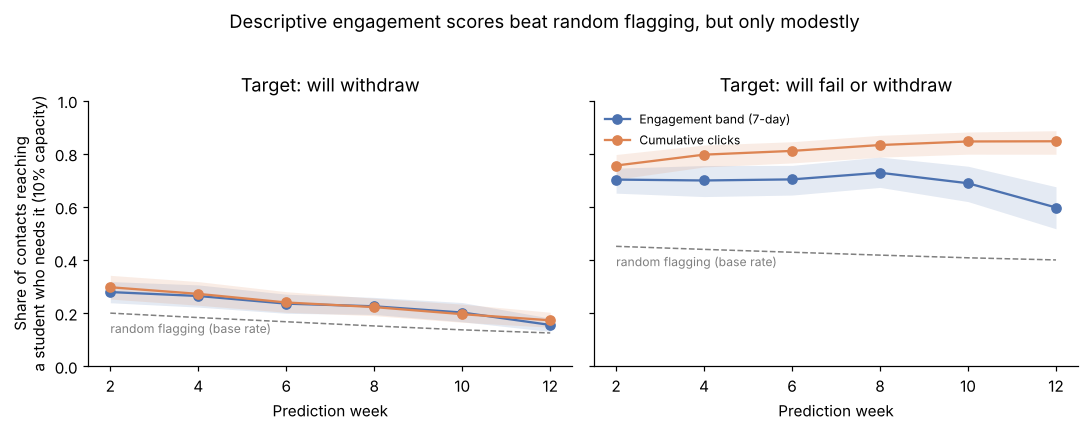

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, target, title in zip(axes, ["will_withdraw", "needs_support"], ["Target: will withdraw", "Target: will fail or withdraw"]):
    for name, c in [("Engagement band (7-day)", "#4C72B0"), ("Cumulative clicks", "#DD8452")]:
        r = res[(res.target == target) & (res.baseline == name)]
        ax.plot(r.week, r.precision, marker="o", color=c, label=name)
        ax.fill_between(r.week, r.precision_lo, r.precision_hi, color=c, alpha=0.15, lw=0)
    br = res[(res.target == target) & (res.baseline == "Cumulative clicks")]
    ax.plot(br.week, br.base_rate, ls="--", color="grey", lw=1)
    ax.text(br.week.iloc[0], br.base_rate.iloc[0] - 0.03, "random flagging (base rate)", color="grey", fontsize=8, ha="left", va="top")
    ax.set(title=title, xlabel="Prediction week", ylim=(0, 1))
axes[0].set_ylabel(f"Share of contacts reaching\na student who needs it ({CONTACT_CAPACITY:.0%} capacity)")
axes[1].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Descriptive engagement scores beat random flagging, but only modestly", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "baseline_precision.png", bbox_inches="tight"); plt.show()

### How much warning do flags give?

Official withdrawal often comes well after a student stops engaging, so warning time is measured two ways: to the official withdrawal date, and to the student's **last VLE activity**. Only the second is warning a tutor can act on.

In [7]:
w = res[res.target == "will_withdraw"].set_index(["baseline", "week"])
w[["median_weeks_to_withdrawal", "median_weeks_to_last_activity", "share_caught_already_inactive"]].round(2)

,,median_weeks_to_withdrawal,median_weeks_to_last_activity,share_caught_already_inactive
baseline,week,,,
Engagement band (7-day),2,8.93,3.43,0.29
Cumulative clicks,2,8.86,2.57,0.33
Engagement band (7-day),4,8.71,1.71,0.38
Cumulative clicks,4,9.57,1.43,0.40
Engagement band (7-day),6,8.71,1.29,0.42
Cumulative clicks,6,9.71,0.43,0.48
Engagement band (7-day),8,7.86,0.29,0.49
Cumulative clicks,8,9.43,-1.00,0.54
Engagement band (7-day),10,8.57,0.86,0.47


In [8]:
gap = pop[pop.withdrawn].merge(last_active, left_on=["code_module", "code_presentation", "id_student"], right_index=True, how="left")
g = gap.withdrawal_day - gap.last_active_day
print(f"Days from last click to official withdrawal: median {g.median():.0f}; >=14 days for {(g >= 14).mean():.0%}; "
      f"{gap.last_active_day.isna().mean():.0%} of withdrawn students never clicked")

Days from last click to official withdrawal: median 9; >=14 days for 34%; 12% of withdrawn students never clicked


## 4. Findings

1. **26% of withdrawals happen before the module starts.** In-course data can't help with these; they need a separate, enrolment-stage process.
2. **A descriptive engagement score is a weak withdrawal predictor.** Contacting the 10% least-engaged students in each cohort each week, 16–30% of contacts reach a future withdrawal, against a base rate of 13–20% (lift about 1.2–1.5×; AUC about 0.60). That catches 13–15% of future withdrawals (95% intervals 11–17%).
3. **The reason: failing students disengage too.** In clicks, students who will fail look like students who will withdraw. For the broader *fail or withdraw* target, the same scores do much better: 60–85% of contacts are well aimed (base rate 40–45%), AUC 0.66–0.73.
4. **Apparent warning time is mostly administrative delay.** Caught withdrawals happen a median of about 9 weeks after the flag, but students' last VLE activity is only 0–3 weeks after it. For later prediction weeks, the cumulative-clicks score flags students who have *already* gone silent (29–56% of catches). The median gap from last click to official withdrawal is 9 days, and 12% of withdrawn students never clicked at all.
5. **Comparing within the cohort matters.** Raw click counts do worse than cohort-relative percentiles, because modules differ a lot in click volume.

**What stage 2/3 needs to deliver:** flags that come **before** a student goes silent. That means trajectory features (a drop from the student's own baseline), assessment behaviour (late or missed submissions), and judging success on warning time before last activity, not just on precision.